# City Temperature Anomalies and Warming Patterns
This project uses a predefined 27-city panel from Berkeley Earth's **GlobalLandTemperaturesByCity.csv**, distributed in Kaggle's Climate Change Earth Surface Temperature Data. All months from 1951 through 2012 are retained before cleaning. The input has eleven sourced attributes: seven city fields plus four global monthly temperature fields from GlobalTemperatures.csv in the same archive, joined many-to-one by month. Global context is repeated across cities and is not an independent local observation. Current global values are excluded from forecast predictors. Calendar, climatology and lag features are labeled as derived attributes.

[Dataset and license](https://www.kaggle.com/datasets/berkeleyearth/climate-change-earth-surface-temperature-data) | [Berkeley Earth](https://berkeleyearth.org/data/). Provenance, selection and hashes: `data/provenance.json`. The data card lists CC BY-NC-SA 4.0; the bundled subset is a noncommercial educational adaptation with attribution.

The baseline is each city's calendar-month mean in 1951-1980. Supervised training uses 1981-2000, expanding validation ends in 1992, 1996 and 2000, and final testing uses 2001-2012. Regression predicts the anomaly for a month from information available before it. Classification predicts anomaly above +1 C, a project-defined event rather than a heatwave or global warming threshold. Earlier test-month observations can inform subsequent one-month forecasts; this is rolling evaluation, not a fixed-origin twelve-year forecast. The city panel is not an area-weighted global mean and ends in 2012.


In [3]:
from pathlib import Path  # Build portable file paths for the bundled data and generated outputs.
import json  # Save audit statistics and chosen parameters in a readable format.
import numpy as np  # Use numeric arrays, trigonometry and missing-value markers.
import pandas as pd  # Load and transform the monthly city data as tables.
import matplotlib.pyplot as plt  # Create, label and export figures.
import seaborn as sns  # Plot distributions and relationships using DataFrame columns.
from IPython.display import display  # Render tables directly below the notebook cell.
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import cross_val_score, GridSearchCV
SEED=42  # Keep stochastic estimator results reproducible.
OUT=Path('outputs'); OUT.mkdir(exist_ok=True)  # Create a local destination for tables, figures and audit files.
sns.set_theme(style='whitegrid')  # Apply a consistent plot style across deliverables.
def savefig(name):  # Use the same export and display settings for every figure.
    plt.tight_layout(); plt.savefig(OUT/(name+'.png'),dpi=140,bbox_inches='tight'); plt.show(); plt.close()  # Fit labels, save the image, display it and release the figure.
raw=pd.read_csv('data/city_temperatures_1951_2012.csv')  # Read the eleven-column joined subset without changing its source file.
df=raw.drop_duplicates().copy()  # Remove exact repeated records while retaining the original DataFrame.
df['date']=pd.to_datetime(df.dt,errors='coerce')  # Parse dates; invalid text becomes NaT and is checked below.
for c in ['AverageTemperature','AverageTemperatureUncertainty']:
    df[c]=pd.to_numeric(df[c],errors='coerce').replace([np.inf,-np.inf],np.nan)  # Coerce nonnumeric or nonfinite temperature entries to missing values.
# Flag structurally implausible readings, not legitimate warm or cold extremes.
invalid=~df.AverageTemperature.between(-90,60) & df.AverageTemperature.notna()  # Flag temperatures outside broad physical bounds without deleting real extremes.
df.loc[invalid,'AverageTemperature']=np.nan  # Treat structurally invalid readings as missing outcomes.
assert not df.duplicated(['City','Country','date']).any()  # Require one record for each city-country-month key.
assert df.date.notna().all()  # Stop if any observation month could not be parsed.
df['city_id']=df.City+' | '+df.Country  # Disambiguate cities that share a name across countries.
def coordinate(s):
    return s.str[:-1].astype(float)*np.where(s.str[-1].isin(['S','W']),-1,1)  # Remove the hemisphere suffix and make south/west coordinates negative.
df['latitude']=coordinate(df.Latitude); df['longitude']=coordinate(df.Longitude)  # Convert both coordinate strings into signed numeric degrees.
df['year']=df.date.dt.year; df['month']=df.date.dt.month  # Extract calendar fields for the reference period and chronological splits.
# Climatology uses only 1951-1980: earlier than every supervised training fold.
reference=df[df.year.between(1951,1980)]  # Use only historical observations that precede all model training.
baseline=reference.groupby(['city_id','month']).AverageTemperature.agg(['mean','count']).rename(columns={'mean':'climatology','count':'baseline_count'})  # Estimate a separate normal temperature for each city and calendar month.
assert baseline.baseline_count.min()>=25  # Require adequate historical coverage for every monthly normal.
baseline.to_csv(OUT/'baseline_climatology.csv')  # Export the reference means and counts so anomalies can be audited.
df=df.join(baseline,on=['city_id','month'])  # Attach the matching historical monthly normal to every observation.
df['anomaly']=df.AverageTemperature-df.climatology  # Remove the local seasonal normal; positive values indicate warmer months.
# Ensure shift(1) means the previous calendar month: no compressed time gaps.
df=df.sort_values(['city_id','date']).reset_index(drop=True)  # Order each city chronologically before constructing past-only features.
assert df.groupby('city_id').date.diff().dropna().dt.days.between(28,31).all()  # Check that adjacent rows are consecutive calendar months within each city.
g=df.groupby('city_id')  # Keep lag calculations separate for every city.
df['lag1_anomaly']=g.anomaly.shift(1)  # Use the previous observed month, never the current target month.
df['lag12_anomaly']=g.anomaly.shift(12)  # Represent the same calendar month in the previous year.
df['prior12_mean']=g.anomaly.transform(lambda x:x.shift(1).rolling(12,min_periods=9).mean())  # Shift first, then average past anomalies to prevent target leakage.
df['lag1_uncertainty']=g.AverageTemperatureUncertainty.shift(1)  # Use only previously available measurement uncertainty.
df['month_sin']=np.sin(2*np.pi*df.month/12); df['month_cos']=np.cos(2*np.pi*df.month/12)  # Encode the circular annual cycle so December and January are neighbors.
df['time_years']=df.year-1981+(df.month-1)/12  # Represent long-term time progression with a fractional monthly component.
df['abs_latitude']=df.latitude.abs()  # Represent distance from the equator regardless of hemisphere.
df['hemisphere']=np.where(df.latitude>=0,'North','South')  # Create a descriptive grouping for geographic comparisons.
# Never impute a missing outcome. Predictors are imputed within each training fold.
model=df[df.year.between(1981,2012)&df.anomaly.notna()].sort_values(['date','city_id']).reset_index(drop=True)  # Keep supervised years with an observed target, then sort all cities by month.
model['warm_month']=(model.anomaly>1.0).astype(int)  # Define the positive class using the stated local +1 C anomaly threshold.
train=model[model.year<=2000].copy().reset_index(drop=True)  # Reserve 1981-2000 for estimator fitting and chronological model selection.
test=model[model.year>=2001].copy().reset_index(drop=True)  # Hold 2001-2012 apart for final performance evaluation.
assert train.date.max()<test.date.min()  # Ensure every training month precedes every final test month.
# Same month across all cities belongs to the same fold. No shuffled panel split.
cv=[]  # Store explicit row indices for expanding chronological validation windows.
for end,val_end in [(1988,1992),(1992,1996),(1996,2000)]:  # Expand training history and validate only on the following years.
    ti=np.flatnonzero(train.year.le(end)); vi=np.flatnonzero(train.year.between(end+1,val_end))  # Keep every city from a month on the same side of the fold boundary.
    assert train.iloc[ti].date.max()<train.iloc[vi].date.min()  # Verify that each validation fold contains only future observations.
    cv.append((ti,vi))  # Reuse identical temporal folds for regression and classification tuning.
num=['time_years','month_sin','month_cos','latitude','longitude','abs_latitude',
     'lag1_anomaly','lag12_anomaly','prior12_mean','lag1_uncertainty']
cat=['city_id']  # Treat city identity as categorical rather than assigning numeric ranks.
features=num+cat  # Select only the documented numeric and categorical predictors.
def preprocessing():  # Return a fresh transformer that each training fold fits independently.
    return ColumnTransformer([('numeric',make_pipeline(SimpleImputer(strategy='median'),StandardScaler()),num),  # Impute numeric gaps and standardize using training-fold statistics.
                             ('city',OneHotEncoder(handle_unknown='ignore',sparse_output=False),cat)])  # Encode city membership; unseen categories receive all-zero city indicators.
Xtr,Xte=train[features],test[features]  # Extract predictor tables without including current outcomes.
print('Raw rows:',len(raw),'Cities:',df.city_id.nunique(),'Engineered columns:',len(df.columns))
print('Train: 1981-2000',len(train),'Test: 2001-2012',len(test))
print('Evaluation is rolling one-month-ahead: prior test-month observations become available sequentially.')


Raw rows: 20088 Cities: 27 Engineered columns: 29
Train: 1981-2000 6480 Test: 2001-2012 3888
Evaluation is rolling one-month-ahead: prior test-month observations become available sequentially.


## Data preparation and exploration

,dt,AverageTemperature,AverageTemperatureUncertainty,City,Country,Latitude,Longitude,LandAverageTemperature,LandMaxTemperature,LandMinTemperature,LandAndOceanAverageTemperature
0,1951-01-01,24.755,0.459,Bangkok,Thailand,13.66N,99.91E,2.138,7.770,-3.521,13.341
1,1951-02-01,26.540,0.250,Bangkok,Thailand,13.66N,99.91E,2.332,8.163,-3.661,13.488
2,1951-03-01,29.049,0.400,Bangkok,Thailand,13.66N,99.91E,5.091,11.074,-1.087,14.278
3,1951-04-01,30.561,0.365,Bangkok,Thailand,13.66N,99.91E,8.367,14.538,2.191,15.198
4,1951-05-01,29.499,0.444,Bangkok,Thailand,13.66N,99.91E,11.438,17.371,5.376,16.158


<class 'pandas.DataFrame'>
RangeIndex: 20088 entries, 0 to 20087
Data columns (total 11 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   dt                              20088 non-null  str    
 1   AverageTemperature              20088 non-null  float64
 2   AverageTemperatureUncertainty   20088 non-null  float64
 3   City                            20088 non-null  str    
 4   Country                         20088 non-null  str    
 5   Latitude                        20088 non-null  str    
 6   Longitude                       20088 non-null  str    
 7   LandAverageTemperature          20088 non-null  float64
 8   LandMaxTemperature              20088 non-null  float64
 9   LandMinTemperature              20088 non-null  float64
 10  LandAndOceanAverageTemperature  20088 non-null  float64
dtypes: float64(6), str(5)
memory usage: 1.7 MB
{'records': 20088, 'source_attributes': 11, 'engineered_attri

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
dt,20088,744,1951-01-01,27,NaN,NaN,NaN,NaN,NaN,NaN,NaN
AverageTemperature,20088.0,NaN,NaN,NaN,16.26216,-18.943,10.88475,16.856,23.35925,36.339,8.876104
AverageTemperatureUncertainty,20088.0,NaN,NaN,NaN,0.334516,0.049,0.224,0.295,0.399,2.561,0.171655
City,20088,27,Bangkok,744,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country,20088,22,United States,2232,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Latitude,20088,24,52.24N,1488,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Longitude,20088,27,99.91E,744,NaN,NaN,NaN,NaN,NaN,NaN,NaN
LandAverageTemperature,20088.0,NaN,NaN,NaN,8.953071,1.882,4.85525,9.272,13.1125,15.482,4.158363
LandMaxTemperature,20088.0,NaN,NaN,NaN,14.654949,7.229,10.42625,14.9915,18.918,21.32,4.258191
LandMinTemperature,20088.0,NaN,NaN,NaN,3.317405,-3.661,-0.74475,3.516,7.3135,9.715,4.058396


Joined source attributes: 11 Engineered attributes: 29


,rows,missing
city_id,,
Bangkok | Thailand,600,0
Berlin | Germany,600,0
Bombay | India,600,0
Cairo | Egypt,600,0
Cape Town | South Africa,600,0
Chicago | United States,600,0
Cordoba | Argentina,600,0
Jakarta | Indonesia,600,0
Lima | Peru,600,0


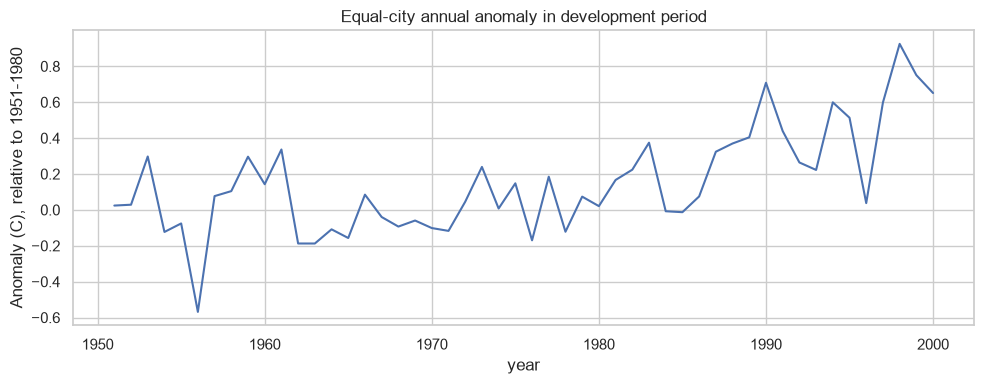

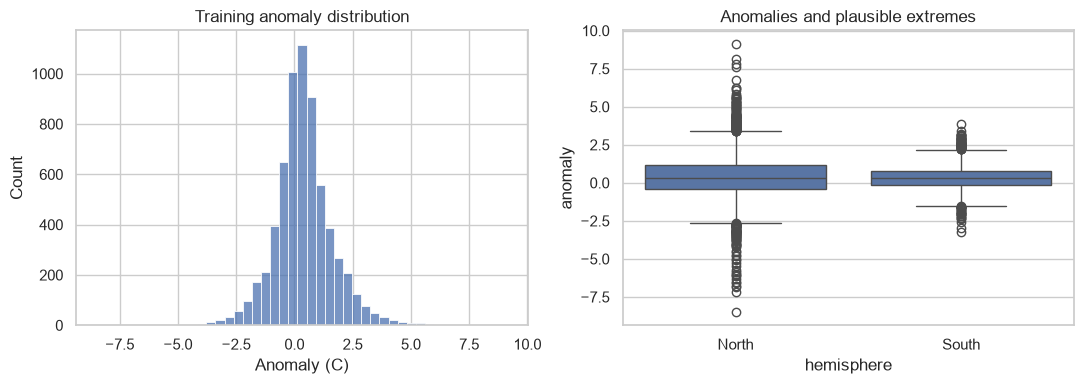

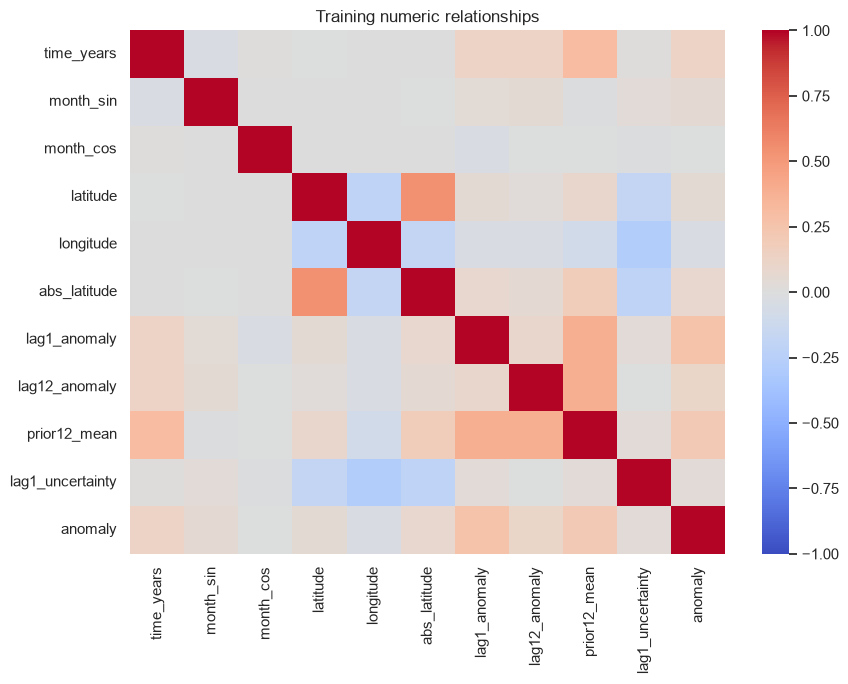

,date,LandAverageTemperature,LandMaxTemperature,LandMinTemperature,LandAndOceanAverageTemperature
count,600,600.000000,600.000000,600.000000,600.000000
mean,1975-12-16 10:57:36,8.812525,14.503962,3.188808,15.391010
min,1951-01-01 00:00:00,1.882000,7.229000,-3.661000,13.298000
25%,1963-06-23 12:00:00,4.665750,10.359000,-0.878250,14.213250
50%,1975-12-16 12:00:00,9.125500,14.830000,3.333500,15.439500
75%,1988-06-08 12:00:00,12.813750,18.634500,7.191250,16.582750
max,2000-12-01 00:00:00,15.340000,20.972000,9.715000,17.609000
std,NaN,4.154977,4.248587,4.065431,1.225962


Local IQR flags retained: 262


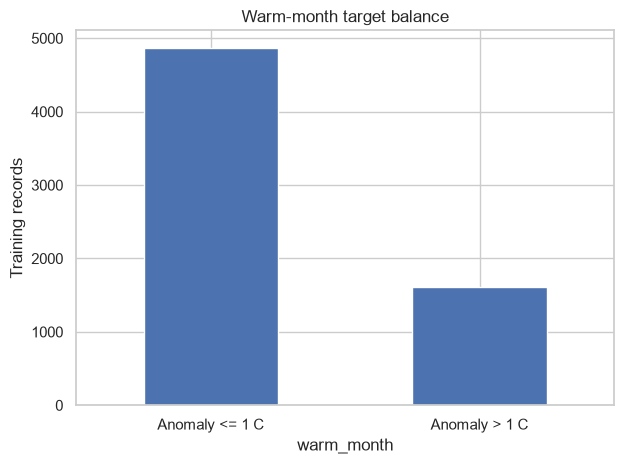

In [4]:
display(raw.head()); raw.info()  # Inspect example records, column types and missingness before analysis.
audit={'records':len(raw),'source_attributes':len(raw.columns),'engineered_attributes':len(df.columns),
       'cities':df.city_id.nunique(),'missing_temperature':int(raw.AverageTemperature.isna().sum()),
       'missing_uncertainty':int(raw.AverageTemperatureUncertainty.isna().sum()),
       'duplicates_removed':len(raw)-len(df),'invalid_temperatures':int(invalid.sum()),
       'missing_target_rows_excluded':int(df[df.year.between(1981,2012)].anomaly.isna().sum()),
       'train_records':len(train),'test_records':len(test)}
(OUT/'audit.json').write_text(json.dumps(audit,indent=2)); print(audit)  # Persist the cleaning and split audit alongside the notebook results.
display(df.describe(include='all').T)
# Save the complete engineered schema separately from the unmodified joined input.
df.to_csv(OUT/'analytical_dataset.csv',index=False)
print('Joined source attributes:',len(raw.columns),'Engineered attributes:',len(df.columns))  # Inspect summary statistics for the full analytical schema.
# Development EDA stops at 2000. Final-period trends are reported only in D4.
dev=df[df.year<=2000]  # Limit exploratory model-development plots to observations through 2000.
coverage=dev.groupby('city_id').agg(rows=('date','size'),missing=('AverageTemperature',lambda x:x.isna().sum()))  # Count available records and missing temperatures separately for each city.
coverage.to_csv(OUT/'coverage.csv');display(coverage)  # Save and display the city-level completeness check.
annual=dev.groupby(['year','city_id']).anomaly.mean().unstack()  # Arrange development-period annual anomalies into year-by-city columns.
annual.mean(axis=1).plot(figsize=(10,4));plt.ylabel('Anomaly (C), relative to 1951-1980');plt.title('Equal-city annual anomaly in development period');savefig('anomaly_trend')  # Plot an equally weighted city average rather than an area-weighted global mean.
fig,ax=plt.subplots(1,2,figsize=(11,4))
sns.histplot(train.anomaly,bins=45,ax=ax[0]);ax[0].set(xlabel='Anomaly (C)',title='Training anomaly distribution')  # Inspect the shape and spread of the training anomaly distribution.
sns.boxplot(data=train,x='hemisphere',y='anomaly',ax=ax[1]);ax[1].set_title('Anomalies and plausible extremes');savefig('distributions')  # Compare hemisphere distributions while retaining plausible extreme anomalies.
plt.figure(figsize=(9,7));sns.heatmap(train[num+['anomaly']].corr(),cmap='coolwarm',center=0,vmin=-1,vmax=1)  # Show training-only numeric correlations to identify redundant predictors.
plt.title('Training numeric relationships');savefig('correlations')
# Global context varies by month, not city; exclude current context from forecasts.
context_cols=['LandAverageTemperature','LandMaxTemperature','LandMinTemperature','LandAndOceanAverageTemperature']
display(dev[['date']+context_cols].drop_duplicates('date').describe())
assert not set(context_cols)&set(features)  # Prevent contemporaneous global information entering forecasts.
# City-month IQR flags respect local seasonality. Keep genuine weather extremes.
bounds=dev.groupby(['city_id','month']).AverageTemperature.quantile([.25,.75]).unstack()  # Calculate local seasonal quartiles instead of pooling unlike city climates.
bounds.columns=['q1','q3'];checked=dev.join(bounds,on=['city_id','month'])  # Attach the first and third quartiles to the corresponding city-month rows.
flag=(checked.AverageTemperature.lt(checked.q1-1.5*(checked.q3-checked.q1))|checked.AverageTemperature.gt(checked.q3+1.5*(checked.q3-checked.q1)))  # Flag values outside 1.5 IQR for inspection without automatically removing them.
print('Local IQR flags retained:',int(flag.sum()))
train.warm_month.value_counts().rename(index={0:'Anomaly <= 1 C',1:'Anomaly > 1 C'}).plot.bar(rot=0)  # Show class imbalance before judging classification accuracy.
plt.ylabel('Training records');plt.title('Warm-month target balance');savefig('class_balance')
# Export cleaned development data, never overwrite the source.
dev.to_csv(OUT/'cleaned_development.csv',index=False)  # Export cleaned development observations separately from the original subset.


## Decisions and implications
The eleven-column joined input exceeds the attribute minimum before feature engineering. Source temperature and uncertainty missingness are audited separately. Missing targets are excluded rather than fabricated; missing predictors are imputed within modeling folds. City-country-date keys must be unique, coordinates are converted with correct hemisphere signs, and consecutive calendar months are verified before lags. Temperatures outside -90 to 60 C are flagged as structural errors; ordinary extreme anomalies remain. Calendar-month climatology removes seasonality before warming comparisons. Correlations, uneven variability and class balance motivate regularization, chronological evaluation and F1/recall. Dataset selection is geographic convenience sampling and cannot support a global mean claim.

## Measured findings and reflection

### Preparation findings

The joined source has 11 attributes and 20,088 observations. Training warm-event prevalence is 25.0%; training anomaly standard deviation is 1.303 C. Local seasonality is removed by reference climatology, and class imbalance motivates warm-event F1 and recall alongside accuracy.